# Evaluation

## Evaluate on different situation

### Load dataset and model

In [1]:
import argparse
import os.path

import torch
from torch import nn, optim
from torch import nn
from torch.utils.data import DataLoader
from tqdm import tqdm
from dataset.dataset_loader import VideoDataset
import torch.nn.functional as F

DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print(DEVICE)
# The parser setting
parser = argparse.ArgumentParser()
parser = VideoDataset.add_model_specific_args(parser)
parser.add_argument('--data_path', type=str, default='dataset/ATR_1F_3F_2024-12-25')
# parser.add_argument('--data_path', type=str, default='dataset/mul_fps_data')

parser.add_argument('--sequence_length', type=int, default=40)
parser.add_argument('--resolution', type=int, default=64)
parser.add_argument('--batch_size', type=int, default=16)
parser.add_argument('--num_workers', type=int, default=8)
parser.add_argument('--LR_RATE', type=int, default=1e-4)
parser.add_argument('--NUM_EPOCHS', type=int, default=100)
parser.add_argument('--iteration_num', type=int, default=1000)
args = parser.parse_args(args=[])
mulgpu = True
rgb = False

# Load the Dataset
Dataset = VideoDataset
dataset = Dataset(args.data_path, args.sequence_length,rgb=rgb, train=True, resolution=args.resolution)

# dataloader for the trainning
dataloader_train = DataLoader(
    dataset,
    batch_size=args.batch_size,
    num_workers=args.num_workers,
    pin_memory=True,
    shuffle=True
)

# dataloader for the evaluation
dataset = Dataset(args.data_path, args.sequence_length, train=False, resolution=args.resolution)
dataloader_val = DataLoader(
    dataset,
    batch_size=args.batch_size,
    num_workers=args.num_workers,
    pin_memory=True,
    shuffle=False
)

from utils import fw_diffusion_vid, fw_diffusion_mot, MixedSequenceMaskGenerator
input_mot_channel = args.sequence_length * 2
mask_generator = MixedSequenceMaskGenerator(t2=args.sequence_length)

# The parameters for forward diffusion process
beta = torch.linspace(1e-4, 0.02, args.iteration_num) 
alpha = 1.0-beta
alpha_cum = torch.tensor([alpha[0]] + [torch.prod(alpha[:i+1]) for i in range(1, len(beta))])


from TimeSformer.VDT_cat_vm import VDT_cat

nhead = 6
depth = 12
patch_size= 2
hidden_size = 768
epoch = 100
in_channels = 6
input_size = 8

eps_est_model = VDT_cat(
    input_size=input_size,
    patch_size=patch_size,
    in_channels=in_channels,
    hidden_size=hidden_size,
    depth=depth,
    num_frames=args.sequence_length,
    num_heads=nhead,
    mlp_ratio=4.0,
    learn_sigma=False
    ).to(DEVICE)


from diffusers.models import AutoencoderKL
vae = AutoencoderKL.from_pretrained(f"stabilityai/sd-vae-ft-mse").to(DEVICE)
vae.encoder.conv_in = nn.Conv2d(9, vae.encoder.conv_in.out_channels, kernel_size=3, stride=1, padding=1)
vae.decoder.conv_out = nn.Conv2d(vae.decoder.conv_out.in_channels, 9, kernel_size=3, stride=1, padding=1)


if mulgpu:
    input_dim = 3
    modelData = 'checkpoints_vae_3c_seg/vae_20250202_seg40.pth.tar'
    checkpoint = torch.load(modelData)
    state_dict = checkpoint['model_state_dict']
    state_dict = {k.replace("module.", ""): v for k, v in state_dict.items()}
else:
    modelData = 'checkpoints_vae_seg/vae_40.pth.tar'
    checkpoint = torch.load(modelData)
    state_dict = checkpoint['model_state_dict']
        

vae = AutoencoderKL.from_pretrained(f"stabilityai/sd-vae-ft-mse")
vae.encoder.conv_in = nn.Conv2d(input_dim, vae.encoder.conv_in.out_channels, kernel_size=3, stride=1, padding=1)
vae.decoder.conv_out = nn.Conv2d(vae.decoder.conv_out.in_channels, input_dim, kernel_size=3, stride=1, padding=1)
vae.load_state_dict(state_dict)
vae.to(DEVICE)

# freeze vae
for param in vae.parameters():
    param.requires_grad = False





cuda:0
metadata exists in: dataset/ATR_1F_3F_2024-12-25/train/metadata_40.pkl
metadata exists in: dataset/ATR_1F_3F_2024-12-25/test/metadata_40.pkl


### Evaluate one single real data's Manhattan distance with other data in the dataset

In [9]:
import numpy as np
np.set_printoptions(threshold=np.inf, linewidth=np.inf)
import random
from eval_3c.utils import manhattan_dist


dec_vid_list = []
rec_mot_list = []

valid_dataset = Dataset(args.data_path, args.sequence_length, rgb=rgb,train=True, resolution=args.resolution)
idx=13180
batch, vid_idx, path = valid_dataset[idx]
batch, mot = dict.values(batch)
mot = mot.reshape(1,2,args.sequence_length).permute(0,2,1).to(DEVICE)

vid = batch.to(DEVICE)
vid = vid.view(-1,64,64,9)
vid_obstacle = vid[:,:,:,0] + vid[:,:,:,1] + vid[:,:,:,3] + vid[:,:,:,4] + vid[:,:,:,5]
vid_human = vid[:,:,:,6]
vid_floor = vid[:,:,:,7]
vid = torch.cat((vid_obstacle.unsqueeze(3), vid_human.unsqueeze(3), vid_floor.unsqueeze(3)), dim=3)


dec_vid_list.append(vid)
rec_mot_list.append(mot[0].reshape(1,args.sequence_length,2))


# 随机抽取 n 个索引
random_indices = random.sample(range(len(valid_dataset)), 50)

# 从数据集中抽取数据
for idx in random_indices:
    batch, vid_idx, path = valid_dataset[idx]
    batch, mot = dict.values(batch)
    mot = mot.reshape(1,2,args.sequence_length).permute(0,2,1).to(DEVICE)
    vid = batch.to(DEVICE)
    vid = vid.view(-1,64,64,9)
    vid_obstacle = vid[:,:,:,0] + vid[:,:,:,1] + vid[:,:,:,3] + vid[:,:,:,4] + vid[:,:,:,5]
    vid_human = vid[:,:,:,6]
    vid_floor = vid[:,:,:,7]
    vid = torch.cat((vid_obstacle.unsqueeze(3), vid_human.unsqueeze(3), vid_floor.unsqueeze(3)), dim=3)

    dec_vid_list.append(vid)
    rec_mot_list.append(mot[0].reshape(1,args.sequence_length,2))


frame_t = 10 
manhattan_distance = manhattan_dist(args, dec_vid_list, rec_mot_list, frame_t, input_dim)
torch.save(manhattan_distance, 'eval_3c/manhattan_distances_1.pt')


metadata exists in: dataset/ATR_1F_3F_2024-12-25/train/metadata_40.pkl


Frame 1 Manhattan Distances: {'background': tensor(0.1331), 'Human': tensor(0.0455), 'Floor': tensor(0.1152)}
Frame 2 Manhattan Distances: {'background': tensor(0.1150), 'Human': tensor(0.0458), 'Floor': tensor(0.0743)}
Frame 3 Manhattan Distances: {'background': tensor(0.0911), 'Human': tensor(0.0461), 'Floor': tensor(0.0527)}
Frame 4 Manhattan Distances: {'background': tensor(0.1730), 'Human': tensor(0.0447), 'Floor': tensor(0.1401)}
Frame 5 Manhattan Distances: {'background': tensor(0.0944), 'Human': tensor(0.0462), 'Floor': tensor(0.0535)}
Frame 6 Manhattan Distances: {'background': tensor(0.1898), 'Human': tensor(0.0539), 'Floor': tensor(0.1454)}
Frame 7 Manhattan Distances: {'background': tensor(0.1455), 'Human': tensor(0.0459), 'Floor': tensor(0.1107)}
Frame 8 Manhattan Distances: {'background': tensor(0.1317), 'Human': tensor(0.0461), 'Floor': tensor(0.1272)}
Frame 9 Manhattan Distances: {'background': tensor(0.1219), 'Human': tensor(0.0463), 'Floor': tensor(0.0781)}
Frame 10 M

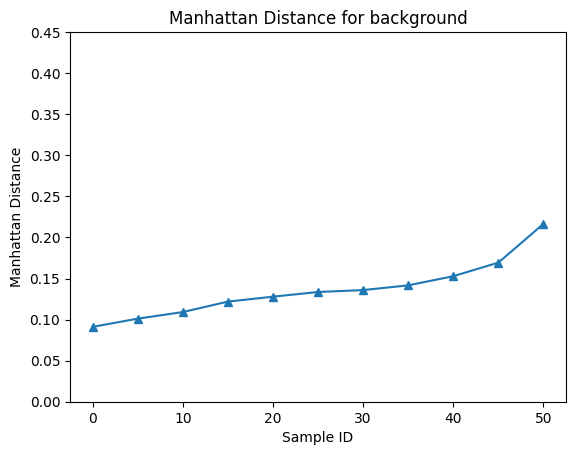

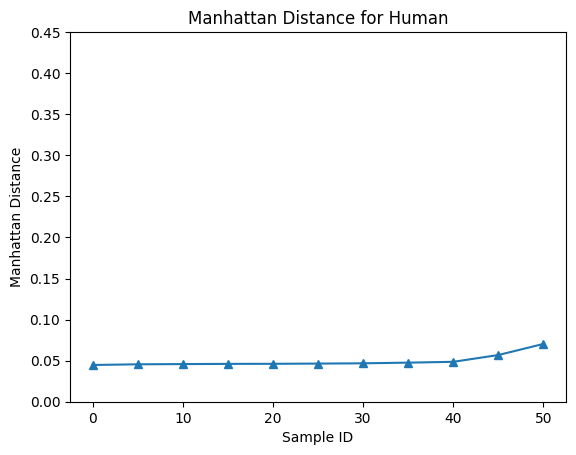

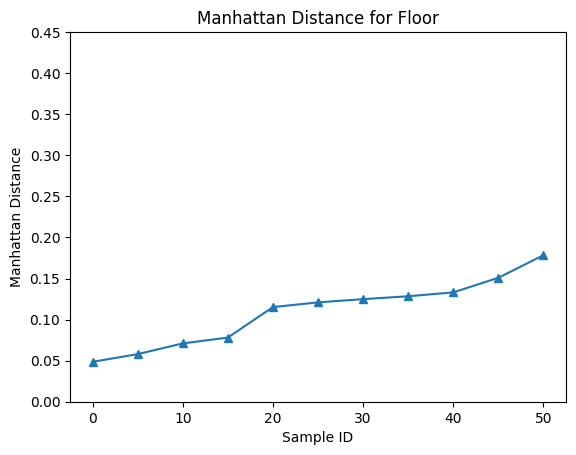

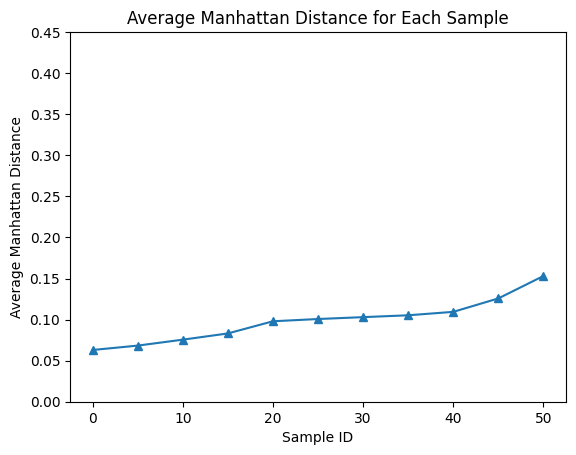

In [10]:
from eval_3c.utils import visual_MD

# 读取 .pt 文件
distances,_ = torch.load('eval_3c/manhattan_distances_1.pt')
# print(distances)
visual_MD(distances)

### Evaluate multiple real data's Manhattan distances and calculate the average

In [ ]:
import numpy as np
np.set_printoptions(threshold=np.inf, linewidth=np.inf)
import random
from eval_3c.utils import manhattan_dist, t3c

all_manhattan_distance = []

valid_dataset = Dataset(args.data_path, args.sequence_length, rgb=rgb,train=True, resolution=args.resolution)

# 从数据集中抽取数据
real_data_random_indices = random.sample(range(len(valid_dataset)), 350)
for real_idx in real_data_random_indices:
    dec_vid_list = []
    rec_mot_list = []

    batch, vid_idx, path = valid_dataset[real_idx]
    batch, mot = dict.values(batch)
    mot = mot.reshape(1,2,args.sequence_length).permute(0,2,1).to(DEVICE)
    
    vid = t3c(batch).to(DEVICE)

    dec_vid_list.append(vid)
    rec_mot_list.append(mot[0].reshape(1,args.sequence_length,2))


    # 随机抽取 n 个索引
    random_indices = random.sample(range(len(valid_dataset)), 50)

    # 从数据集中抽取数据
    for idx in random_indices:
        batch, vid_idx, path = valid_dataset[idx]
        batch, mot = dict.values(batch)
        mot = mot.reshape(1,2,args.sequence_length).permute(0,2,1).to(DEVICE)
        vid = t3c(batch).to(DEVICE)

        dec_vid_list.append(vid)
        rec_mot_list.append(mot[0].reshape(1,args.sequence_length,2))

    frame_t = 10 
    manhattan_distance, _ = manhattan_dist(args, dec_vid_list, rec_mot_list, frame_t, input_dim)
    all_manhattan_distance.append(manhattan_distance)

# 将字典写入文件
torch.save(all_manhattan_distance, 'eval_3c/all_manhattan_distances.pt')



In [4]:
import torch

# 读取 .pt 文件
all_distances = torch.load('eval_3c/all_manhattan_distances_500x50.pt')
# print((all_distances))
# 初始化字典以存储排序后的结果
all_sorted_distances = []
channels = ['background', 'Human', 'Floor']

print(len(all_distances))
for distances,_ in all_distances:

    channel_distances = {channel: [] for channel in channels}
    sorted_sample_distances = {}
    for sample, distance in distances.items():
        for channel in channels:
            channel_distances[channel].append(distance[channel].item())
    
    for channel in channels:
        channel_distances[channel] = sorted(channel_distances[channel])

    all_sorted_distances.append(channel_distances)

# # 将结果存储为字典
# torch.save(all_sorted_distances, 'eval_3c/sorted_manhattan_distances_real_data.pt')

# 初始化字典以存储每个样本的平均曼哈顿距离
average_distances = {f'Sample {i+1}': {channel: 0 for channel in channels} for i in range(50)}
# print(average_distances)
# all_distances = torch.load('eval_3c/sorted_manhattan_distances_real_data.pt')

# 遍历所有曼哈顿距离，计算每个样本的总和
for distances in all_sorted_distances:
    for channel, distance in distances.items():
        for t, dist in enumerate(distance):
            # print(average_distances['Sample ' + str(t+1)][channel])
            average_distances['Sample ' + str(t+1)][channel] += dist

# 计算每个样本的平均曼哈顿距离
for t, distance in average_distances.items():
    average_distances[t] = {channel: torch.tensor(dist / len(all_sorted_distances)) for channel, dist in distance.items()}

# 打印每个样本的平均曼哈顿距离
print("Average Manhattan Distances for Each Sample:")
for sample, means in average_distances.items():
    print(f"{sample}: {means}")

# 将结果存储为字典
torch.save(average_distances, 'eval_3c/average_manhattan_distances_real_data.pt')

350
Average Manhattan Distances for Each Sample:
Sample 1: {'background': tensor(0.0762), 'Human': tensor(0.0093), 'Floor': tensor(0.0572)}
Sample 2: {'background': tensor(0.0836), 'Human': tensor(0.0099), 'Floor': tensor(0.0642)}
Sample 3: {'background': tensor(0.0876), 'Human': tensor(0.0102), 'Floor': tensor(0.0681)}
Sample 4: {'background': tensor(0.0903), 'Human': tensor(0.0104), 'Floor': tensor(0.0709)}
Sample 5: {'background': tensor(0.0924), 'Human': tensor(0.0105), 'Floor': tensor(0.0731)}
Sample 6: {'background': tensor(0.0943), 'Human': tensor(0.0106), 'Floor': tensor(0.0749)}
Sample 7: {'background': tensor(0.0961), 'Human': tensor(0.0106), 'Floor': tensor(0.0767)}
Sample 8: {'background': tensor(0.0980), 'Human': tensor(0.0107), 'Floor': tensor(0.0783)}
Sample 9: {'background': tensor(0.0998), 'Human': tensor(0.0107), 'Floor': tensor(0.0800)}
Sample 10: {'background': tensor(0.1015), 'Human': tensor(0.0108), 'Floor': tensor(0.0817)}
Sample 11: {'background': tensor(0.1032)

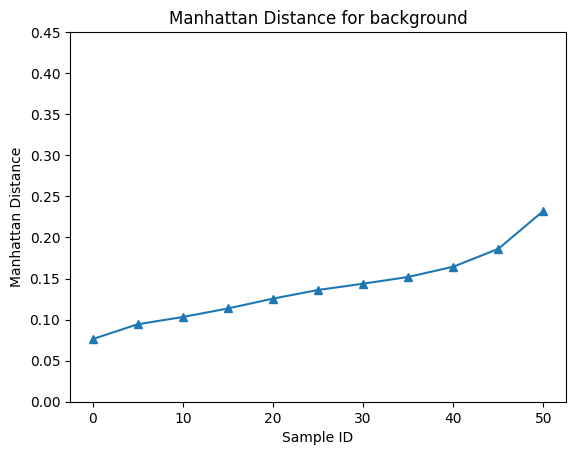

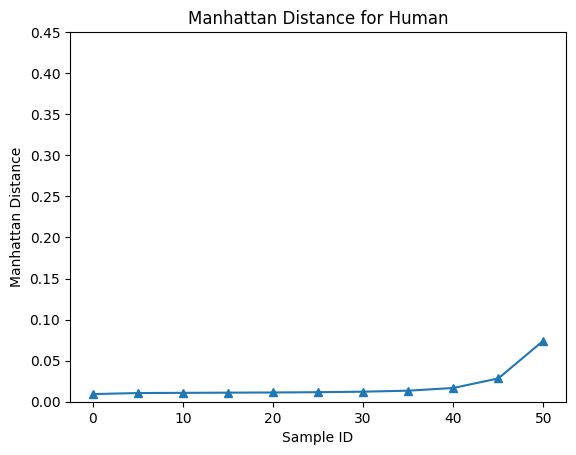

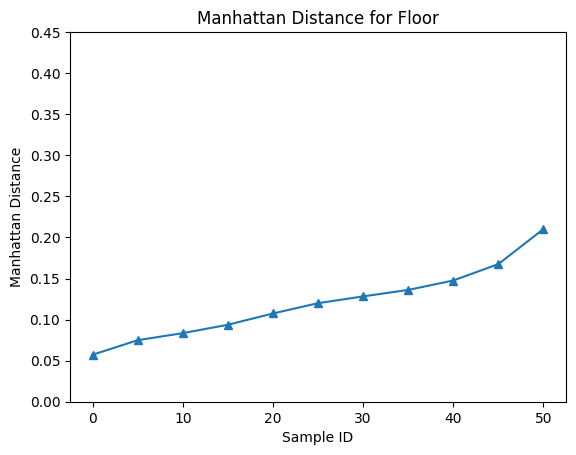

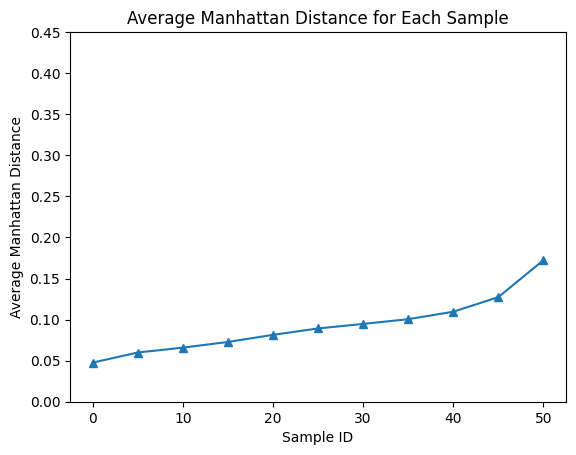

In [7]:
from eval_3c.utils import visual_MD

# 读取 .pt 文件
distances = torch.load('eval_3c/average_manhattan_distances_real_data.pt')
visual_MD(distances)

### Evaluate real data v.s. generated samples

In [ ]:
import numpy as np
np.set_printoptions(threshold=np.inf, linewidth=np.inf)

from DDIM.ddim import ddim_generator
from utils import mask_vid_mot, visual_vid_mmot, gray3c_2color
import time
from eval_3c.utils import manhattan_dist, t3c
import random

all_manhattan_distance = []

# modelData = 'checkpoints_mmVDT_cat_vae_seg/VDT_20241031_halfmask_rgb_xacti_5fps_seq40_mgpu_d'+str(depth)+'_h'+str(hidden_size)+'_nh'+str(nhead)+'_np'+str(patch_size)+'_it'+str(args.iteration_num)+'_'+str(epoch)+'.pth.tar'
modelData = 'checkpoints_mmVDT_vae_3c_seg/VDT_20250203_ATR_1F_3F_seg_3c_seq40_mgpu_d'+str(depth)+'_h'+str(hidden_size)+'_nh'+str(nhead)+'_np'+str(patch_size)+'_it'+str(args.iteration_num)+'_'+str(epoch)+'.pth.tar'
# modelData = 'checkpoints_mmVDT_cat_vae_seg/VDT_20241220_test_halfmask_seg_xacti_5fps_seq40_mgpu_d'+str(depth)+'_h'+str(hidden_size)+'_nh'+str(nhead)+'_np'+str(patch_size)+'_it'+str(args.iteration_num)+'_'+str(epoch)+'.pth.tar'

ddim_generator = ddim_generator(nit=args.iteration_num,patch_size=patch_size,nhead=nhead,input_size=input_size, in_channels=in_channels, 
                                depth=depth, hidden_size=hidden_size, model_path=modelData, sequence_length=args.sequence_length,_cuda=0, cat=True)

valid_dataset = Dataset(args.data_path, args.sequence_length, rgb=rgb,train=True, resolution=args.resolution)

# 从数据集中抽取数据
real_data_random_indices = random.sample(range(len(valid_dataset)), 500)
for real_idx in real_data_random_indices:
    vis_id = 0 # the index for visualization, default = 0
    pred_num = 50 # The number of multiple predictions
    frame_t = 10 

    test = True
    batch, vid_idx, path = valid_dataset[real_idx]
    print(vid_idx, path)
    batch, mot = dict.values(batch)

    mot = mot.reshape(1,2,args.sequence_length).permute(0,2,1).to(DEVICE)
    start_time = time.time()

    vid = t3c(batch).permute(0,3,1,2).to(DEVICE)
    enc_vid = vae.encode(vid).latent_dist.sample()
    enc_vid = enc_vid.reshape(1, args.sequence_length,4,8,8).permute(0,1,3,4,2)

    a = enc_vid.to(DEVICE)
    b = mot.to(DEVICE)
    rec_vid_list = []
    rec_mot_list = []
    dec_vid_list = []

    ################ Original image #############################
    batch = batch.permute(0,3,1,2)
    dec_vid_list.append(vid.permute(0,2,3,1))
    rec_mot_list.append(b[vis_id].reshape(1,args.sequence_length,2))

    if rgb:
        batch_rgb = batch
    else:
        batch_rgb = gray3c_2color(batch)
        batch_rgb = torch.clamp(batch_rgb, 0,1)

    rec_vid_list.append(batch_rgb.permute(0,2,3,1))  
    # visual_vid_mmot(batch_rgb.permute(0,2,3,1), b[vis_id].reshape(1,args.sequence_length,2), rgb=True, frame_t=frame_t,grid=False)

    if test:
        diff_a = torch.randn([pred_num,args.sequence_length,input_size,input_size,in_channels-2]).to(DEVICE)
        diff_b = torch.randn([pred_num,args.sequence_length,2]).to(DEVICE)

    # Choose a mask type from 0 to 2
    # 0: prediction 1: backward 2: interpolation, t means the current frame
    mask_vid, mask_motion, _ = mask_generator(diff_a,diff_b, idx=0, t=frame_t)

    a = a.repeat(pred_num,1,1,1,1)
    b = b.repeat(pred_num,1,1)
    diff_a, diff_b = mask_vid_mot(mask_vid,mask_motion, a, b, diff_a, diff_b)

    with torch.no_grad():
        rec_vid, rec_mot = ddim_generator(diff_a,diff_b,mask_vid,mask_motion,ncal=16) #ncal: the ddim sample steps
     
    rec_vid = rec_vid.reshape(pred_num,args.sequence_length,input_size,input_size,in_channels-2).permute(0,1,4,2,3)

    ################ Decode image #############################
    for i in range(pred_num):  
        rec_mot_list.append(rec_mot[i]) 
        # print(rec_vid[i].permute(0,2,3,1)[0,5,0])
        dec_vid = vae.decode(rec_vid[i]).sample
        dec_vid_list.append(dec_vid.permute(0,2,3,1))
        # print(dec_vid_list[i].shape)
        if rgb:
            dec_rgb = torch.clamp(dec_vid, 0,1).permute(0,2,3,1)
        else:
            dec_rgb = gray3c_2color(dec_vid)
            dec_rgb = torch.clamp(dec_rgb, 0,1).permute(0,2,3,1)
        rec_vid_list.append(dec_rgb)
    
    manhattan_distance, _ = manhattan_dist(args, dec_vid_list, rec_mot_list, frame_t, input_dim, vis_list = [False, False, False])
    all_manhattan_distance.append(manhattan_distance)

# 将字典写入文件
torch.save(all_manhattan_distance, 'eval_3c/all_generated_manhattan_distances_500x50.pt')




500
Average Manhattan Distances for Each Sample:
Sample 1: {'background': tensor(0.0576), 'Human': tensor(0.0082), 'Floor': tensor(0.0460)}
Sample 2: {'background': tensor(0.0609), 'Human': tensor(0.0085), 'Floor': tensor(0.0493)}
Sample 3: {'background': tensor(0.0631), 'Human': tensor(0.0087), 'Floor': tensor(0.0514)}
Sample 4: {'background': tensor(0.0649), 'Human': tensor(0.0089), 'Floor': tensor(0.0530)}
Sample 5: {'background': tensor(0.0664), 'Human': tensor(0.0090), 'Floor': tensor(0.0546)}
Sample 6: {'background': tensor(0.0677), 'Human': tensor(0.0091), 'Floor': tensor(0.0558)}
Sample 7: {'background': tensor(0.0691), 'Human': tensor(0.0092), 'Floor': tensor(0.0571)}
Sample 8: {'background': tensor(0.0703), 'Human': tensor(0.0094), 'Floor': tensor(0.0583)}
Sample 9: {'background': tensor(0.0714), 'Human': tensor(0.0095), 'Floor': tensor(0.0594)}
Sample 10: {'background': tensor(0.0725), 'Human': tensor(0.0096), 'Floor': tensor(0.0605)}
Sample 11: {'background': tensor(0.0737)

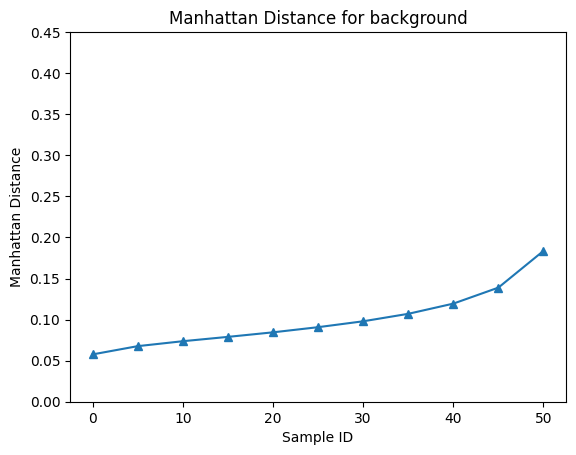

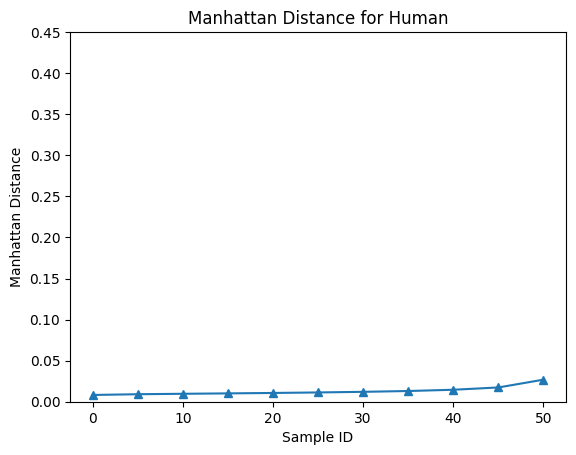

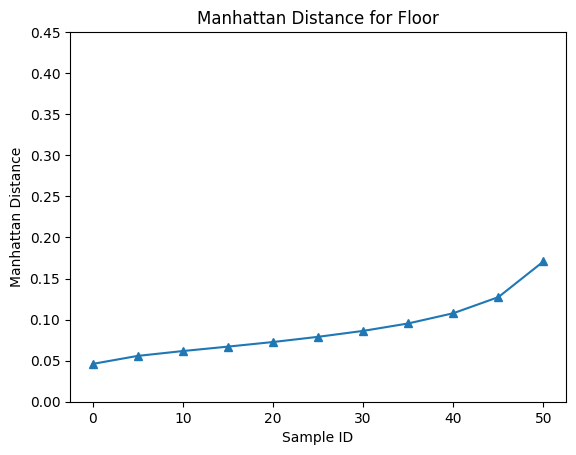

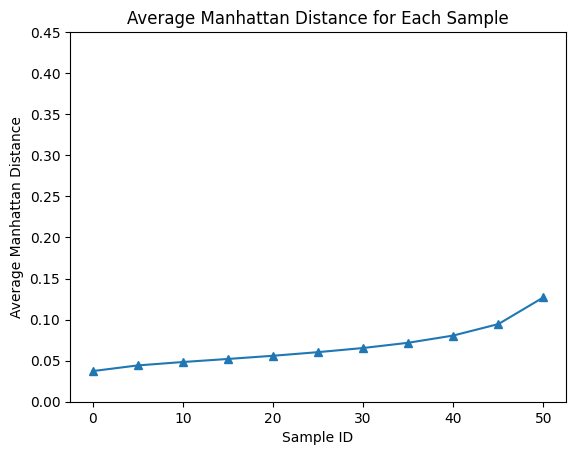

In [4]:
import torch

# 读取 .pt 文件
all_distances = torch.load('eval_3c/all_generated_manhattan_distances_500x50.pt')

# 初始化字典以存储排序后的结果
all_sorted_distances = []
channels = ['background', 'Human', 'Floor']

print(len(all_distances))
for distances in all_distances:

    channel_distances = {channel: [] for channel in channels}
    sorted_sample_distances = {}
    for sample, distance in distances.items():
        for channel in channels:
            channel_distances[channel].append(distance[channel].item())
    
    for channel in channels:
        channel_distances[channel] = sorted(channel_distances[channel])

    all_sorted_distances.append(channel_distances)

# # 将结果存储为字典
# torch.save(all_sorted_distances, 'eval/sorted_manhattan_distances_generated.pt')

# 初始化字典以存储每个样本的平均曼哈顿距离
average_distances = {f'Sample {i+1}': {channel: 0 for channel in channels} for i in range(50)}
# print(average_distances)
# sorted_distances = torch.load('eval/sorted_manhattan_distances_generated.pt')

# 遍历所有曼哈顿距离，计算每个样本的总和
for distances in all_sorted_distances:
    for channel, distance in distances.items():
        for t, dist in enumerate(distance):
            # print(average_distances['Sample ' + str(t+1)][channel])
            average_distances['Sample ' + str(t+1)][channel] += dist

# 计算每个样本的平均曼哈顿距离
for t, distance in average_distances.items():
    average_distances[t] = {channel: torch.tensor(dist / len(all_sorted_distances)) for channel, dist in distance.items()}

# 打印每个样本的平均曼哈顿距离
print("Average Manhattan Distances for Each Sample:")
for sample, means in average_distances.items():
    print(f"{sample}: {means}")

# 将结果存储为字典
torch.save(average_distances, 'eval_3c/average_manhattan_distances_generated.pt')

# Visualize the results
from eval_3c.utils import visual_MD

# 读取 .pt 文件
distances = torch.load('eval_3c/average_manhattan_distances_generated.pt')
visual_MD(distances)

## Summarize three figure in one

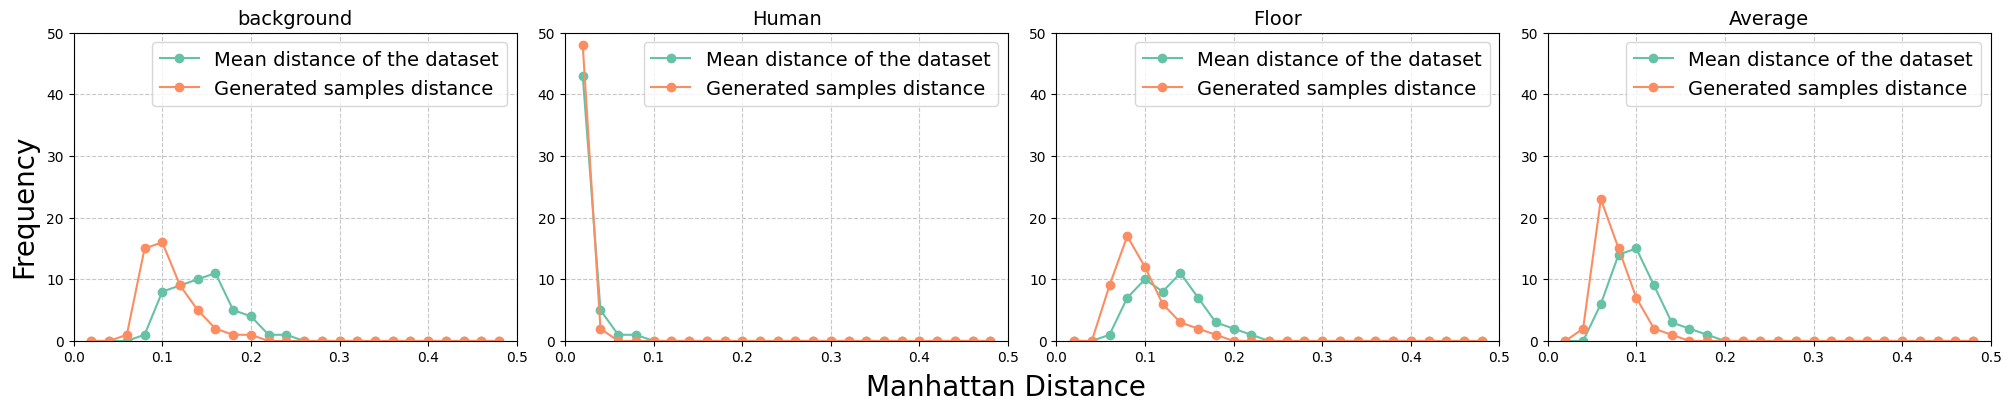

In [1]:
import torch
manhattan_distance_1 = torch.load('eval_3c/manhattan_distances_1.pt')
manhattan_distance_2 = torch.load('eval_3c/average_manhattan_distances_real_data.pt')
manhattan_distance_3 = torch.load('eval_3c/average_manhattan_distances_generated.pt')
# print(manhattan_distance_2)
from eval_3c.utils import visual_MD_combined
visual_MD_combined(manhattan_distance_2, manhattan_distance_3, Freq=True)    

## Evaluate generated data on time axis

In [5]:
import numpy as np
np.set_printoptions(threshold=np.inf, linewidth=np.inf)

from DDIM.ddim import ddim_generator
from utils import mask_vid_mot, visual_vid_mmot, gray3c_2color
import time
from eval_3c.utils import manhattan_dist, t3c
import random

all_manhattan_distance = []
# modelData = 'checkpoints_mmVDT_cat_vae_seg/VDT_20241031_halfmask_rgb_xacti_5fps_seq40_mgpu_d'+str(depth)+'_h'+str(hidden_size)+'_nh'+str(nhead)+'_np'+str(patch_size)+'_it'+str(args.iteration_num)+'_'+str(epoch)+'.pth.tar'
modelData = 'checkpoints_mmVDT_vae_3c_seg/VDT_20250203_ATR_1F_3F_seg_3c_seq40_mgpu_d'+str(depth)+'_h'+str(hidden_size)+'_nh'+str(nhead)+'_np'+str(patch_size)+'_it'+str(args.iteration_num)+'_'+str(epoch)+'.pth.tar'
# modelData = 'checkpoints_mmVDT_cat_vae_seg/VDT_20241220_test_halfmask_seg_xacti_5fps_seq40_mgpu_d'+str(depth)+'_h'+str(hidden_size)+'_nh'+str(nhead)+'_np'+str(patch_size)+'_it'+str(args.iteration_num)+'_'+str(epoch)+'.pth.tar'

ddim_generator = ddim_generator(nit=args.iteration_num,patch_size=patch_size,nhead=nhead,input_size=input_size, in_channels=in_channels, 
                                depth=depth, hidden_size=hidden_size, model_path=modelData, sequence_length=args.sequence_length,_cuda=0, cat=True)

valid_dataset = Dataset(args.data_path, args.sequence_length, rgb=rgb,train=True, resolution=args.resolution)

# 从数据集中抽取数据
real_data_random_indices = random.sample(range(len(valid_dataset)), 10)
for real_idx in real_data_random_indices:
    vis_id = 0 # the index for visualization, default = 0
    pred_num = 100 # The number of multiple predictions
    frame_t = 10 

    test = True
    batch, vid_idx, path = valid_dataset[real_idx]
    print(vid_idx, path)
    batch, mot = dict.values(batch)

    mot = mot.reshape(1,2,args.sequence_length).permute(0,2,1).to(DEVICE)
    start_time = time.time()

    vid = t3c(batch).permute(0,3,1,2).to(DEVICE)
    enc_vid = vae.encode(vid).latent_dist.sample()
    enc_vid = enc_vid.reshape(1, args.sequence_length,4,8,8).permute(0,1,3,4,2)

    a = enc_vid.to(DEVICE)
    b = mot.to(DEVICE)
    rec_vid_list = []
    rec_mot_list = []
    dec_vid_list = []

    ################ Original image #############################
    batch = batch.permute(0,3,1,2)
    dec_vid_list.append(vid.permute(0,2,3,1))
    rec_mot_list.append(b[vis_id].reshape(1,args.sequence_length,2))
    if rgb:
        batch_rgb = batch
    else:
        batch_rgb = gray3c_2color(batch)
        batch_rgb = torch.clamp(batch_rgb, 0,1)

    # visual_vid_mmot(batch_rgb.permute(0,2,3,1), b[vis_id].reshape(1,args.sequence_length,2), rgb=True, frame_t=frame_t,grid=False)

    if test:
        diff_a = torch.randn([pred_num,args.sequence_length,input_size,input_size,in_channels-2]).to(DEVICE)
        diff_b = torch.randn([pred_num,args.sequence_length,2]).to(DEVICE)

    # Choose a mask type from 0 to 2
    # 0: prediction 1: backward 2: interpolation, t means the current frame
    mask_vid, mask_motion, _ = mask_generator(diff_a,diff_b, idx=0, t=frame_t)


    a = a.repeat(pred_num,1,1,1,1)
    b = b.repeat(pred_num,1,1)
    diff_a, diff_b = mask_vid_mot(mask_vid,mask_motion, a, b, diff_a, diff_b)

    with torch.no_grad():
        rec_vid, rec_mot = ddim_generator(diff_a,diff_b,mask_vid,mask_motion,ncal=16) #ncal: the ddim sample steps
        
    rec_vid = rec_vid.reshape(pred_num,args.sequence_length,input_size,input_size,in_channels-2).permute(0,1,4,2,3)

    ################ Decode image #############################
    for i in range(pred_num):  
        rec_mot_list.append(rec_mot[i]) 
        # print(rec_vid[i].permute(0,2,3,1)[0,5,0])
        dec_vid = vae.decode(rec_vid[i]).sample
        dec_vid_list.append(dec_vid.permute(0,2,3,1))
        if rgb:
            dec_rgb = torch.clamp(dec_vid, 0,1).permute(0,2,3,1)
        else:
            dec_rgb = gray3c_2color(dec_vid)
            dec_rgb = torch.clamp(dec_rgb, 0,1).permute(0,2,3,1)
        rec_vid_list.append(dec_rgb)
    manhattan_distance,_ = manhattan_dist(args, dec_vid_list, rec_mot_list, frame_t, input_dim, mean=False)
    all_manhattan_distance.append(manhattan_distance)

torch.save(all_manhattan_distance, 'eval_3c/all_generated_time_10x100_2.pt')


load model: success
metadata exists in: dataset/ATR_1F_3F_2024-12-25/train/metadata_40.pkl
128 dataset/ATR_1F_3F_2024-12-25/train/2024-07-16_14-51-32/20.mp4
Frame 1 Manhattan Distances: {'background': tensor([0.0474, 0.0808, 0.0701, 0.0725, 0.0693, 0.0925, 0.0789, 0.0928, 0.0911,
        0.0859, 0.1160, 0.0979, 0.1145, 0.1104, 0.1113, 0.1069, 0.1055, 0.0933,
        0.1304, 0.2534, 0.1936, 0.1975, 0.1626, 0.1616, 0.1494, 0.1702, 0.1228,
        0.1116, 0.1082, 0.1079]), 'Human': tensor([0.0059, 0.0093, 0.0049, 0.0049, 0.0066, 0.0066, 0.0073, 0.0066, 0.0105,
        0.0134, 0.0105, 0.0068, 0.0088, 0.0107, 0.0095, 0.0139, 0.0093, 0.0095,
        0.0085, 0.0093, 0.0073, 0.0100, 0.0076, 0.0056, 0.0088, 0.0051, 0.0063,
        0.0066, 0.0049, 0.0071]), 'Floor': tensor([0.0376, 0.0623, 0.0552, 0.0537, 0.0515, 0.0803, 0.0645, 0.0737, 0.0759,
        0.0688, 0.0969, 0.0891, 0.1045, 0.1084, 0.1038, 0.1125, 0.1006, 0.0815,
        0.1248, 0.2295, 0.1741, 0.1624, 0.1460, 0.1392, 0.1318, 0.1467, 0

In [13]:
import torch

# 读取 .pt 文件
all_distances = torch.load('eval_3c/all_generated_time_10x100_2.pt')

# 初始化字典以存储排序后的结果
all_sorted_distances = []
channels = ['background', 'Human', 'Floor']

print(len(all_distances))
for distances in all_distances:

    channel_distances = {channel: [] for channel in channels}
    sorted_sample_distances = {}
    for sample, distance in distances.items():
        for channel in channels:
            # print(distance)
            channel_distances[channel].append(distance[channel])

    all_sorted_distances.append(channel_distances)
# print(all_sorted_distances)

# 初始化字典以存储每个样本的平均曼哈顿距离
average_distances = {f'Sample {i+1}': {channel: 0 for channel in channels} for i in range(100)}
# print(average_distances)

# 遍历所有曼哈顿距离，计算每个样本的总和
for distances in all_sorted_distances:
    for channel, distance in distances.items():
        for t, dist in enumerate(distance):
            # print(average_distances['Sample ' + str(t+1)][channel])
            average_distances['Sample ' + str(t+1)][channel] += dist

# 计算每个样本的平均曼哈顿距离
for t, distance in average_distances.items():
    average_distances[t] = {channel: torch.tensor(dist / len(all_sorted_distances)) for channel, dist in distance.items()}

# 打印每个样本的平均曼哈顿距离
print("Average Manhattan Distances for Each Sample:")
for sample, means in average_distances.items():
    print(f"{sample}: {means}")

# 将结果存储为字典
torch.save(average_distances, 'eval/average_manhattan_distances_time_generated.pt')



10
Average Manhattan Distances for Each Sample:
Sample 1: {'background': tensor([0.0355, 0.0449, 0.0491, 0.0521, 0.0499, 0.0582, 0.0613, 0.0771, 0.0598,
        0.0559, 0.0601, 0.0569, 0.0683, 0.0713, 0.0930, 0.0847, 0.1118, 0.0766,
        0.0903, 0.0924, 0.0952, 0.0731, 0.0739, 0.0754, 0.0704, 0.0758, 0.0953,
        0.0787, 0.0814, 0.0804]), 'Human': tensor([0.0092, 0.0106, 0.0096, 0.0095, 0.0109, 0.0107, 0.0128, 0.0135, 0.0105,
        0.0100, 0.0096, 0.0091, 0.0148, 0.0163, 0.0150, 0.0170, 0.0101, 0.0121,
        0.0118, 0.0103, 0.0123, 0.0108, 0.0097, 0.0104, 0.0096, 0.0104, 0.0103,
        0.0110, 0.0111, 0.0123]), 'Floor': tensor([0.0239, 0.0313, 0.0372, 0.0393, 0.0370, 0.0470, 0.0493, 0.0703, 0.0502,
        0.0483, 0.0494, 0.0461, 0.0526, 0.0567, 0.0775, 0.0733, 0.1008, 0.0695,
        0.0804, 0.0788, 0.0842, 0.0587, 0.0607, 0.0619, 0.0579, 0.0633, 0.0857,
        0.0677, 0.0708, 0.0686])}
Sample 2: {'background': tensor([0.0361, 0.0837, 0.0733, 0.0900, 0.0759, 0.1074, 0.0818

In [14]:
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
import numpy as np

# 读取 .pt 文件
distances = torch.load('eval/average_manhattan_distances_time_generated.pt')


# 定义 channel 名称和颜色
# channels = ['undetected_obs', 'ceiling', 'wall', 'detected_furniture', 'door', 'Human', 'Floor']
channels = ['background', 'Human', 'Floor']

colors = sns.color_palette("Set2", n_colors=8)

# 提取每个 channel 的曼哈顿距离
channel_distances = {channel: [] for channel in channels}

for sample, distance in distances.items():
    for channel in channels:
        channel_distances[channel].append(distance[channel].tolist())


(30, 41)
(30, 27)
(30, 32)
background 41
(30, 51)
(30, 43)
(30, 6)
Human 51
(30, 40)
(30, 29)
(30, 31)
Floor 40


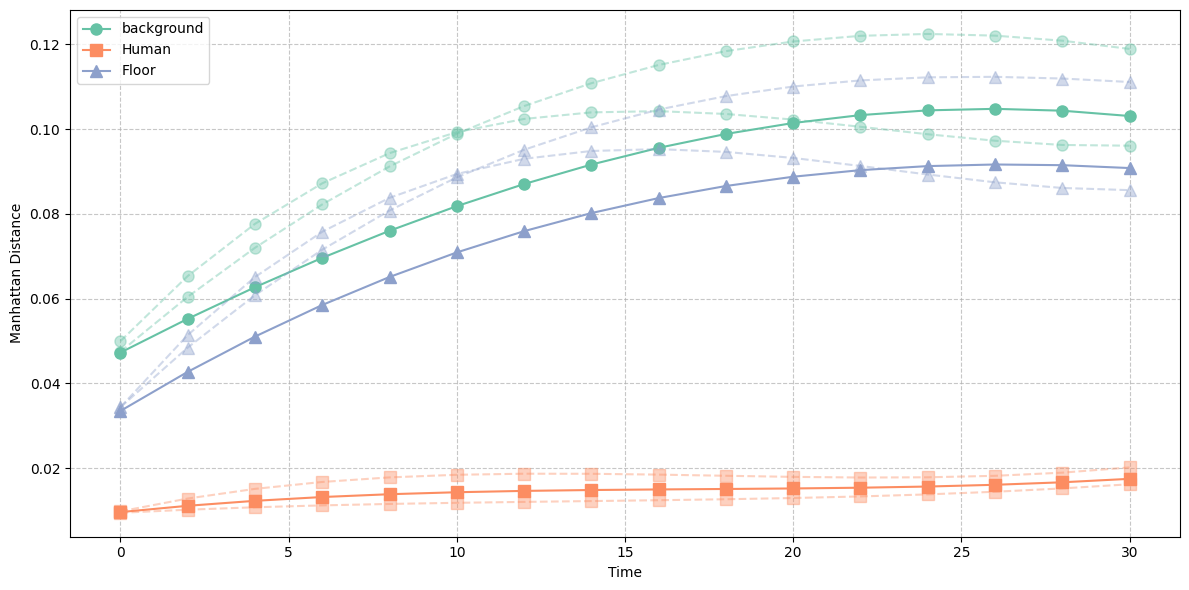

In [15]:
# 设置时间间距
time_interval = 2

# 设置分组数量
n_clusters = 3

# 绘制拟合曲线
plt.figure(figsize=(12, 6))
marker = ['o', 's', '^', 'x', '*', '2', '<', '>',  '3', '4', 'v', 'D']

max_num = 0
for i, (channel, color) in enumerate(zip(channels, colors)):
    # 将每个样本的曼哈顿距离转换为 numpy 数组，并转置为 [t=30, sample个数] 的形式
    data = np.array(channel_distances[channel]).T

    # 使用 KMeans 将数据分成 n_clusters 组
    kmeans = KMeans(n_clusters=n_clusters, random_state=0).fit(data.T)
    labels = kmeans.labels_

    # 计算时间点
    time_points = np.arange(0, len(data))

    for cluster in range(n_clusters):
        group = data[:, labels == cluster]
        if group.shape[1] > max_num:
            max_num = group.shape[1]

    for cluster in range(n_clusters):
        # 分别提取每组数据
        group = data[:, labels == cluster]
        print(group.shape)
        # 拟合每组数据
        group_mean = np.mean(group, axis=1)
        poly = np.poly1d(np.polyfit(time_points, group_mean, 3))
        time_step = time_points[::time_interval]
        time_step = np.append(time_step, len(data))
        # print(time_step)

       # 绘制数据点和拟合曲线
        if group.shape[1] == max_num:  # 只为第一个 cluster 添加图例条目
            plt.plot(time_step, poly(time_step),marker[i]+'-', label=f'{channel}', color=color, markersize=8)
        else:
            plt.plot(time_step, poly(time_step), marker[i]+'--', color=color, alpha=0.4, markersize=8)
    print(channel, max_num)
    max_num = 0


plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.xlabel('Time')
plt.ylabel('Manhattan Distance')
# plt.title('Manhattan Distance Over Time for Each Channel')

plt.tight_layout()
plt.show()

(30, 100)
<module 'time' (built-in)>
(30, 85) (0.4, 0.7607843137254902, 0.6470588235294118)
(30, 15) (0.9882352941176471, 0.5529411764705883, 0.3843137254901961)
(30, 100)
<module 'time' (built-in)>
(30, 72) (0.4, 0.7607843137254902, 0.6470588235294118)
(30, 28) (0.9882352941176471, 0.5529411764705883, 0.3843137254901961)
(30, 100)
<module 'time' (built-in)>
(30, 72) (0.4, 0.7607843137254902, 0.6470588235294118)
(30, 28) (0.9882352941176471, 0.5529411764705883, 0.3843137254901961)
(30, 100)
<module 'time' (built-in)>
(30, 57) (0.4, 0.7607843137254902, 0.6470588235294118)
(30, 43) (0.9882352941176471, 0.5529411764705883, 0.3843137254901961)


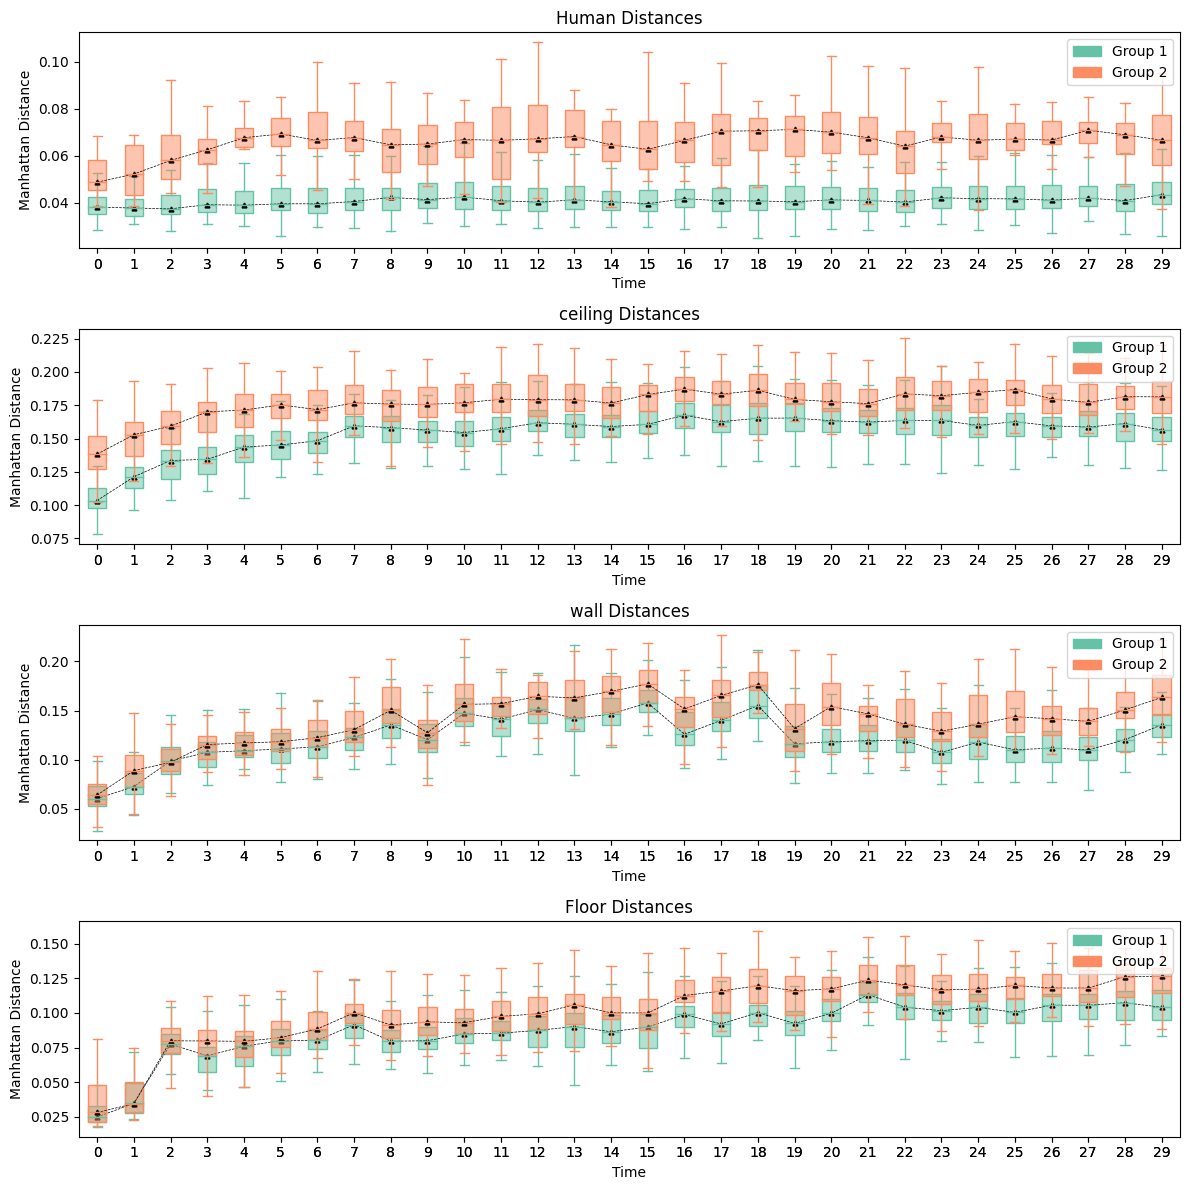

In [94]:
import matplotlib.patches as mpatches
from sklearn.cluster import KMeans
import matplotlib.colors as mcolors

# 设置时间间距
time_interval = 1

# 设置分组数量
n_clusters = 2
# 绘制箱形图
plt.figure(figsize=(12, 12))

for i, (channel, color) in enumerate(zip(channels, colors)):
    # 将每个样本的曼哈顿距离转换为 numpy 数组，并转置为 [t=30, sample个数] 的形式
    data = np.array(channel_distances[channel]).T
    print(data.shape)
    # 使用 KMeans 将数据分成 n_clusters 组
    kmeans = KMeans(n_clusters=n_clusters, random_state=0).fit(data.T)
    labels = kmeans.labels_

    # 计算时间点
    time_points = np.arange(0, len(data) * time_interval, time_interval)
    print(time)
    plt.subplot(len(channels), 1, i + 1)
    for cluster in range(n_clusters):
        # 分别提取每组数据
        group = data[:, labels == cluster]
        color_idx = colors[cluster % len(colors)]
        if group.shape[1] > 50:
            color_idx = colors[0]
        else:
            color_idx = colors[1]

        # 设置透明度
        facecolor = mcolors.to_rgba(color_idx, alpha=0.5)
        edgecolor = mcolors.to_rgba(color_idx, alpha=1.0)
        # 绘制箱形图
        data_to_plot = [group[t] for t in range(len(group))]
        box = plt.boxplot(data_to_plot, positions=time_points, patch_artist=True,
                    boxprops=dict(facecolor=facecolor, color=edgecolor),
                    medianprops=dict(color=edgecolor),
                    whiskerprops=dict(color=edgecolor),
                    capprops=dict(color=edgecolor),
                    showfliers=False,
                    widths=0.5)
        print(group.shape,color_idx)
        # 提取中位数值并连线
        medians = [item.get_ydata()[0] for item in box['medians']]
        plt.plot(time_points, medians, color='black', linestyle='--', linewidth=0.5, marker='^',markersize=3.5)


    plt.xlabel('Time')
    plt.ylabel('Manhattan Distance')
    plt.title(f'{channel} Distances')
    # plt.xticks(np.arange(0, len(data), step=5))  # 设置横坐标为 0, 5, 10, 15, 20, 25, 30
    # 创建图例条目
    legend_patches = [mpatches.Patch(color=colors[cluster % len(colors)], label=f'Group {cluster + 1}') for cluster in range(n_clusters)]
    plt.legend(handles=legend_patches, loc='upper right')

    # y_tick = np.arange(0, 0.3, 0.05)
    # plt.yticks(y_tick)

plt.tight_layout()
plt.show()


In [ ]:
plt.figure(figsize=(12, 12))

#  计算所有 channel 的平均曼哈顿距离
average_distances = np.mean([np.array(channel_distances[channel]) for channel in channels], axis=0).T

# 使用 KMeans 将平均数据分成 n_clusters 组
kmeans = KMeans(n_clusters=n_clusters, random_state=0).fit(average_distances.T)
labels = kmeans.labels_

# 计算时间点
time_points = np.arange(0, len(average_distances) * time_interval, time_interval)

plt.subplot(len(channels) + 1, 1, 1)
for cluster in range(n_clusters):
    # 分别提取每组数据
    group = average_distances[:, labels == cluster]
    print(group.shape)
    # 设置透明度
    facecolor = mcolors.to_rgba(color_idx, alpha=0.5)
    edgecolor = mcolors.to_rgba(color_idx, alpha=1.0)
    # 绘制箱形图
    data_to_plot = [group[t] for t in range(len(group))]
    box = plt.boxplot(data_to_plot, positions=time_points, patch_artist=True,
                boxprops=dict(facecolor=facecolor, color=edgecolor),
                medianprops=dict(color=edgecolor),
                whiskerprops=dict(color=edgecolor),
                capprops=dict(color=edgecolor),
                showfliers=False,
                widths=0.5)
    print(group.shape,color_idx)
    # 提取中位数值并连线
    medians = [item.get_ydata()[0] for item in box['medians']]
    plt.plot(time_points, medians, color='black', linestyle='--', linewidth=0.5, marker='^',markersize=3.5)
    
plt.xlabel('Time')
plt.ylabel('Manhattan Distance')
plt.title('Average Distances')
plt.xticks(np.arange(0, len(average_distances), step=5))  # 设置横坐标为 0, 5, 10, 15, 20, 25, 30
# 创建图例条目
legend_patches = [mpatches.Patch(color=colors[cluster % len(colors)], label=f'Group {cluster + 1}') for cluster in range(n_clusters)]
plt.legend(handles=legend_patches, loc='upper right')

plt.tight_layout()
plt.show()
